# Comparando agrupamientos y representaciones de VOC

La libreta didáctica explica cómo funciona BERTopic. Esta libreta **lee resultados guardados** para comparar decisiones. No ajusta UMAP/HDBSCAN, no carga el encoder y no llama a un LLM. Los experimentos se ejecutan mediante `voc-ml topics study`.

G compara un cambio de configuración sobre las mismas 1.000 reseñas. R compara palabras sobre un único agrupamiento fijo. Los resultados de la muestra no representan una evaluación del corpus completo ni una medida de exactitud.

## 1. Identificando el estudio

Copia el `study_id` devuelto por el CLI. Se requiere una identidad explícita, nunca se elige automáticamente la última ejecución. Usa el kernel del Operador.


In [71]:
import json
from pathlib import Path
from uuid import uuid4

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from voc.paths import data_root
from voc.topics import read_topics
from voc.datasets.shared.manifest import file_hash
from voc.embeddings.shared.contracts import canonical_json
from voc_ml.topics.store import TopicRunStore
from voc_ml.topics.studies import inspect_study

STUDY_ID = "066c6cfc-49ef-40bc-b548-c3eee3dfeced"
store = TopicRunStore(data_root())
study = inspect_study(STUDY_ID, store=store)
print("Protocolo:", study["protocol_sha256"])
print("Muestra:", study["protocol"]["input"]["sample_size"])
print("Dataset:", study["protocol"]["input"]["dataset"]["artifact_id"])


Protocolo: 82928c7b57b2ea8b178f4d8411987de131afa6ebe99d8c2ba5f9b17dcbcf629d
Muestra: 1000
Dataset: 3862e53a-e9f4-47af-a644-35c2cc7c1945


## 2. Leyendo todos los intentos

Una ejecución fallida o pendiente permanece visible. G0 es reutilizado y mantiene su identidad original. Una menor proporción de registros sin asignación puede acompañarse de grupos demasiado amplios, por lo que no basta para elegir una configuración.


,entry,state,seed,rows,topic_count,unassigned_fraction,median_topic_size,maximum_topic_size,worker_wall_seconds,peak_worker_rss_bytes
0,G0-13,completed,13,1000,24,0.044,22.5,375,9.739947,949760000
1,G0-42,reused,42,1000,35,0.162,19.0,65,16.614441,1177853952
2,G0-73,completed,73,1000,36,0.154,21.0,59,9.808481,949186560
3,G1-42,completed,42,1000,34,0.125,20.0,73,11.697949,949596160
4,G2-42,completed,42,1000,17,0.168,41.0,179,9.758008,949026816
5,G3-13,completed,13,1000,40,0.185,16.5,59,9.891221,949170176
6,G3-42,completed,42,1000,40,0.195,17.5,59,9.760346,947269632
7,G3-73,completed,73,1000,38,0.172,20.0,59,9.723626,949571584
8,R0,reused,42,1000,40,0.195,17.5,59,9.760346,947269632
9,R1,completed,42,1000,40,0.195,17.5,59,8.613342,1684254720


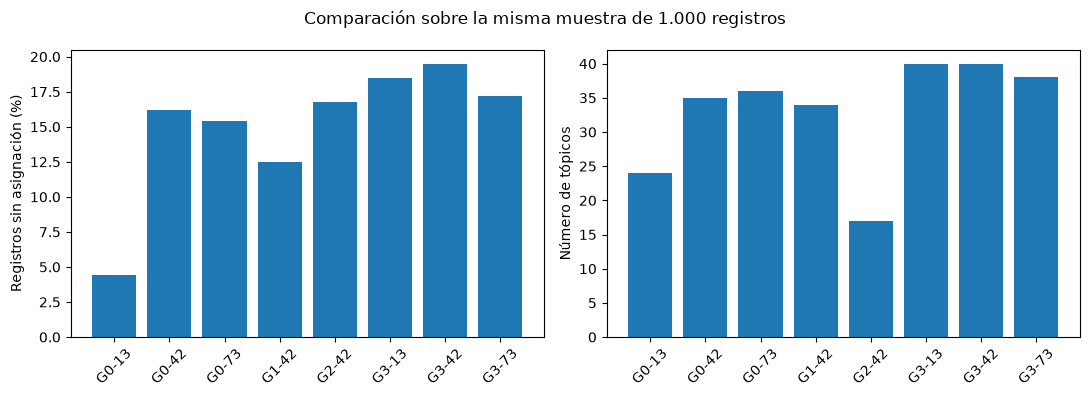

In [72]:
summary = pd.DataFrame(study["summaries"])
columns = ["entry", "state", "seed", "rows", "topic_count", "unassigned_fraction",
           "median_topic_size", "maximum_topic_size", "worker_wall_seconds", "peak_worker_rss_bytes"]
display(summary.reindex(columns=columns))
grouping = summary[summary.entry.str.startswith("G")].copy()
completed = grouping[grouping.state.isin(["completed", "reused"])].copy()
figures = {}
if not completed.empty:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].bar(completed.entry, completed.unassigned_fraction * 100)
    axes[0].set_ylabel("Registros sin asignación (%)")
    axes[1].bar(completed.entry, completed.topic_count)
    axes[1].set_ylabel("Número de tópicos")
    for ax in axes:
        ax.tick_params(axis="x", rotation=45)
    fig.suptitle("Comparación sobre la misma muestra de 1.000 registros")
    fig.tight_layout()
    figures["cobertura-y-topicos"] = fig
    plt.show()


## 3. Tamaños y estabilidad

Los IDs de tópicos son locales a cada ajuste. El ARI compara particiones sin exigir la misma numeración. Reportamos una versión que trata `-1` como grupo y otra que lo excluye de ambas ejecuciones. Una intersección pequeña limita la segunda cifra. Ninguna mide por sí sola corrección semántica.

Las semillas 13 y 73 se ejecutan únicamente para las configuraciones preseleccionadas. Su ausencia significa que esa comprobación está pendiente, no que el resultado sea estable.


,left,right,rows,ari_including_unassigned,ari_assigned_intersection,assigned_intersection_rows,became_assigned,became_unassigned,unassigned_policy
0,G0-42,G0-13,1000,0.264140,0.360197,818,138,20,"-1 is one group in the first ARI, excluded fro..."
1,G0-42,G0-42,1000,1.000000,1.000000,838,0,0,"-1 is one group in the first ARI, excluded fro..."
2,G0-42,G0-73,1000,0.552321,0.920097,775,71,63,"-1 is one group in the first ARI, excluded fro..."
3,G0-42,G1-42,1000,0.494853,0.840545,780,95,58,"-1 is one group in the first ARI, excluded fro..."
4,G0-42,G2-42,1000,0.474130,0.615805,765,67,73,"-1 is one group in the first ARI, excluded fro..."
5,G0-42,G3-13,1000,0.502351,0.871429,755,60,83,"-1 is one group in the first ARI, excluded fro..."
6,G0-42,G3-42,1000,0.831209,0.921099,805,0,33,"-1 is one group in the first ARI, excluded fro..."
7,G0-42,G3-73,1000,0.500333,0.882355,760,68,78,"-1 is one group in the first ARI, excluded fro..."
8,G0-13,G0-73,1000,0.242933,0.333181,828,18,128,"-1 is one group in the first ARI, excluded fro..."
9,G3-42,G3-13,1000,0.524905,0.934880,739,76,66,"-1 is one group in the first ARI, excluded fro..."


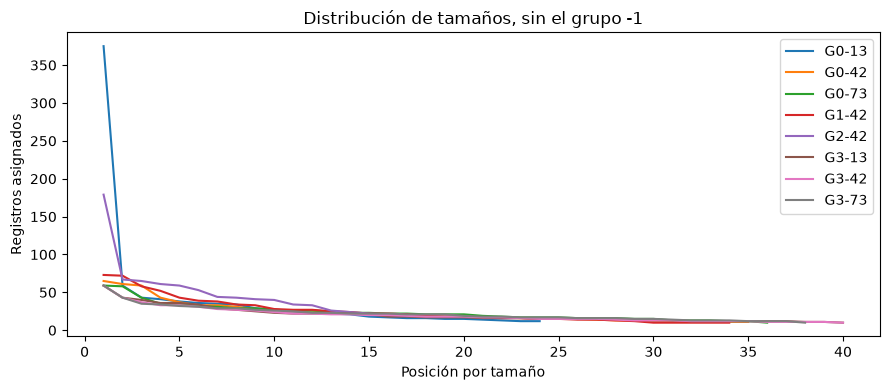

In [73]:
comparisons = pd.DataFrame(study["comparisons"])
display(comparisons)
size_rows = []
for item in study["summaries"]:
    if item["entry"].startswith("G"):
        for rank, size in enumerate(sorted(item.get("topic_sizes", []), reverse=True), 1):
            size_rows.append({"entry": item["entry"], "rank": rank, "size": size})
sizes = pd.DataFrame(size_rows)
if not sizes.empty:
    fig, ax = plt.subplots(figsize=(9, 4))
    for name, part in sizes.groupby("entry", sort=False):
        ax.plot(part["rank"], part["size"], label=name)
    ax.set(xlabel="Posición por tamaño", ylabel="Registros asignados",
           title="Distribución de tamaños, sin el grupo -1")
    ax.legend()
    fig.tight_layout()
    figures["tamanos"] = fig
    plt.show()


## 4. Revisando ejemplos sin escoger solo los favorables

El producto selecciona los tres grupos mayores y hasta tres adicionales con semilla 42. Presenta hasta tres ejemplos por grupo y cinco IDs sin asignación. La pauta evalúa asunto compartido, especificidad de producto y coherencia entre palabras y ejemplos. Cada valoración de 0 a 2 necesita autoría y justificación.

Las plantillas comienzan pendientes. No convertimos la ausencia de revisión en ceros ni atribuimos al equipo una revisión automática. Los textos son material privado bajo `data/` y deben retirarse de las salidas antes de publicar la libreta.


In [74]:
review_rows = []
for entry, template in study["review_templates"].items():
    for topic in template["topics"]:
        review_rows.append({"entry": entry, "topic_id": topic["topic_id"], "size": topic["size"],
                            "words": ", ".join(k["term"] for k in topic["keywords"]),
                            "evidence_ids": topic["evidence_ids"], "reviewer": topic["reviewer"],
                            "scores": topic["scores"], "note": topic["note"]})
review_table = pd.DataFrame(review_rows)
display(review_table)
# Para leer un grupo concreto, usa sus ejemplos verificados, por ejemplo:
# study["review_templates"]["G0-42"]["topics"][0]["evidence"]


,entry,topic_id,size,words,evidence_ids,reviewer,scores,note
0,G0-13,0,375,"no, deja, te, banamex, puedo, no puedo, ya, no...","[appbot:498483038:3695755445, play:com.citiban...",None,None,None
1,G0-13,1,59,"excelente excelente, excelente, excelente geni...",[play:com.citibanamex.banamexmobile:0035bcf8-0...,None,None,None
2,G0-13,2,43,"buena muy, muy buena, buena, muy, ago, te dan,...",[play:com.citibanamex.banamexmobile:07d3c09d-8...,None,None,None
3,G0-13,16,16,"excelente servicio, servicio excelente, servic...",[play:com.citibanamex.banamexmobile:21dcfee1-e...,None,None,None
4,G0-13,4,38,"eficiente, práctica, muy práctica, muy útil, e...",[play:com.citibanamex.banamexmobile:6015480c-0...,None,None,None
...,...,...,...,...,...,...,...,...
61,R2,1,43,"muy buena, buena definitivamente, buena fue, b...",[play:com.citibanamex.banamexmobile:bc99204b-1...,None,None,None
62,R2,2,37,"buena app, app, mucho app, bien app, app graci...","[apple_rss:498483038:14664247669, play:com.cit...",None,None,None
63,R2,27,14,"bien gracias, bueno gracias, buena gracias, ex...",[play:com.citibanamex.banamexmobile:a1640de4-6...,None,None,None
64,R2,6,28,"banca móvil, aplicación bancaria, peor app, ba...",[play:com.citibanamex.banamexmobile:e4709d99-f...,None,None,None


In [75]:
from html import escape
from IPython.display import HTML

# Cambia la variante sin cambiar los ejemplos seleccionados por el protocolo.
REVIEW_ENTRY = "R0"
for topic in study["review_templates"][REVIEW_ENTRY]["topics"]:
    print(f"{REVIEW_ENTRY} · tópico {topic['topic_id']} · {topic['size']} registros")
    print(", ".join(k["term"] for k in topic["keywords"]))
    for example in topic["evidence"]:
        # Escapa el contenido para mostrar las reseñas como texto, nunca como HTML.
        record_id = escape(str(example["record_id"]))
        text = escape(str(example["model_text"]))
        display(HTML(
            '<div style="margin: 0.8em 0; padding: 0.8em 1em; '
            'border-left: 3px solid #888; max-width: 100%;">'
            f'<div style="overflow-wrap: anywhere;"><strong>ID:</strong> {record_id}</div>'
            '<div style="white-space: pre-wrap; overflow-wrap: anywhere; '
            f'line-height: 1.6; margin-top: 0.5em;">{text}</div>'
            '</div>'
        ))
print("IDs sin asignación:", study["review_templates"][REVIEW_ENTRY]["unassigned_ids"])


R0 · tópico 0 · 59 registros
excelente excelente, excelente, excelente genial, genial, genial excellent, excellent excelente, excellent, excelente siempre, excelente 10, excelente calidad


R0 · tópico 1 · 43 registros
buena muy, muy buena, buena, ago, transferencia muy, buena definitivamente, ago transferencia, buenay, buena fue, buenay excelente


R0 · tópico 2 · 37 registros
app muy, buena app, bien app, app gracias, mejorada, mucho app, app solo, estaría, exelente app, llegan notificaciones


R0 · tópico 27 · 14 registros
bien gracias, gracias muy, gracias, gracias todo, excelente gracias, buena gracias, todo bien, ustedes tienen, problemas ordenador, ordenador excelente


R0 · tópico 6 · 28 registros
nómina, bancos, otros, te, peor, otros bancos, debo, peores, así, puedes


R0 · tópico 30 · 13 registros
dinero banamex, dinero, tc, revisé, cajero, centro citibanamex, poder, uber, banamex porque, citibanamex


IDs sin asignación: ['appbot:498483038:3736075338', 'appbot:498483038:3745979768', 'play:com.citibanamex.banamexmobile:20cbae5e-920e-4b5a-9db4-ab05f32e9ac8', 'play:com.citibanamex.banamexmobile:e3e38081-26ac-41e4-98a5-34e1778d0265', 'x:1998488655841927579']


## 5. Comparando palabras sobre un padre fijo

R0 reutiliza c-TF-IDF. R1 emplea KeyBERTInspired y R2 añade MMR. Cambian las palabras, no las asignaciones ni los ejemplos publicados. Los pesos c-TF-IDF y las similitudes coseno tienen significados diferentes y no se comparan numéricamente entre métodos.

La inferencia de términos y ejemplos realizada por R1/R2 pertenece al pipeline. Aquí solo leemos su registro de costo y la representación resultante.


In [76]:
representation_rows = []
representation_costs = []
for key in ("R0", "R1", "R2"):
    entry = study["entries"].get(key)
    if not entry or entry["state"] not in ("completed", "reused"):
        continue
    bundle = read_topics(store.directory(entry["run_id"]) / "release",
                         manifest_sha256=entry["manifest_sha256"])
    chosen_ids = [t["topic_id"] for t in study["review_templates"][key]["topics"]]
    for topic_id in chosen_ids:
        topic = bundle.topic(topic_id)
        representation_rows.append({"variant": key, "topic_id": topic_id,
                                    "words": ", ".join(k["term"] for k in topic["keywords"]),
                                    "evidence_ids": topic["evidence_ids"]})
    encoder = bundle.execution.get("fit", {}).get("encoder") or {}
    representation_costs.append({"variant": key, "run_id": entry["run_id"],
                                 "new_inference": key != "R0", **encoder})
representations = pd.DataFrame(representation_rows)
if representations.empty:
    print("Comparación R pendiente. La libreta no inicia refinamientos.")
else:
    word_table = representations.pivot(index="topic_id", columns="variant", values="words")
    # Muestra todas las palabras y ajusta las líneas para comparar sin truncamiento.
    display(word_table.style.format(escape="html").set_properties(**{
        "white-space": "normal", "overflow-wrap": "anywhere",
        "max-width": "26em", "text-align": "left", "vertical-align": "top"
    }))
    display(pd.DataFrame(representation_costs))


variant,R0,R1,R2
topic_id,,,
0,"excelente excelente, excelente, excelente genial, genial, genial excellent, excellent excelente, excellent, excelente siempre, excelente 10, excelente calidad","excelente, excelente excelente, genial excelente, genial excellent, excelente genial, genial, excellent, excellent excelente, excelente siempre, calidad excelente","excelente, excelente excelente, excellent excelente, excelente siempre, calidad excelente, excelente calidad, aplicación excelente, 10 excelente, excelente 10, excelente aplicación"
1,"buena muy, muy buena, buena, ago, transferencia muy, buena definitivamente, ago transferencia, buenay, buena fue, buenay excelente","muy buena, buena definitivamente, buena fue, buena muy, muy buenay, buenay excelente, buena, buena parece, buena ya, buena te","muy buena, buena definitivamente, buena fue, buena muy, muy buenay, buenay excelente, buena ya, banco muy, soluciona muchas, ago transferencia"
2,"app muy, buena app, bien app, app gracias, mejorada, mucho app, app solo, estaría, exelente app, llegan notificaciones","buena app, app, mucho app, bien app, app gracias, exelente app, app muy, app solo, notificaciones sms, movimientos puedes","buena app, app, mucho app, bien app, app gracias, exelente app, app muy, notificaciones sms, movimientos puedes, más amigable"
6,"nómina, bancos, otros, te, peor, otros bancos, debo, peores, así, puedes","banca móvil, aplicación bancaria, peor app, bancos, otros bancos, préstamo, pagar mínimo, cuando necesitas, cabe recalcar, 000","banca móvil, aplicación bancaria, peor app, bancos, otros bancos, préstamo, pagar mínimo, cuando necesitas, recalcar no, peores"
27,"bien gracias, gracias muy, gracias, gracias todo, excelente gracias, buena gracias, todo bien, ustedes tienen, problemas ordenador, ordenador excelente","bien gracias, bueno gracias, buena gracias, excelente gracias, gracias buenas, gracias bien, gracias gusta, gracias todo, gracias muy, muchas gracias","bien gracias, bueno gracias, buena gracias, excelente gracias, gracias buenas, gracias todo, gracias muy, muchas gracias, buenas noches, problemas ordenador"
30,"dinero banamex, dinero, tc, revisé, cajero, centro citibanamex, poder, uber, banamex porque, citibanamex","numero telefonico, pago realizado, dinero banamex, números tarjeta, pago tard, dinero, opciones pagos, banamex porque, pagar otro, número funcionar","numero telefonico, dinero banamex, números tarjeta, opciones pagos, número funcionar, numero, centro citibanamex, otro viaje, operador final, operador"


,variant,run_id,new_inference,descriptor,encoded_unique,inference_seconds,load_seconds,requested_texts,reused_texts,truncated_unique
0,R0,76a579c2-7199-4cc9-aea0-a9ee4cb10ed5,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,R1,ba17bcbf-b0bc-4a7a-9bca-9c739c2e7754,True,{'adapter': 'sentence-transformers-cpu-f32-thr...,1305.0,2.252042,0.643188,1328.0,23.0,2.0
2,R2,1b7de0f0-3e09-49d9-b5be-7e1571697469,True,{'adapter': 'sentence-transformers-cpu-f32-thr...,1346.0,2.705248,0.590821,2599.0,1253.0,2.0


## 6. Interpretación y siguiente escala

Documenta la elección o conserva G0 si no hay una ventaja defendible. Considera cobertura, ejemplos, estabilidad y recursos conjuntamente. La preselección y el padre R se registran desde el CLI con autoría y motivo.

El procesamiento completo necesita su propio presupuesto y una ampliación explícita de los límites actuales. La libreta didáctica seguirá usando G0. Una futura libreta de resultados leerá los nuevos artefactos, sin volver a ejecutar modelos para regenerar figuras.

## Exportando evidencia

Exportamos las tablas y figuras para preparar el reporte.


In [77]:
destination = data_root() / "reports/topics/studies" / STUDY_ID / str(uuid4())
destination.mkdir(parents=True, exist_ok=False)
for name, table in {"ejecuciones": summary, "comparaciones": comparisons, "tamanos": sizes,
                    "revision": review_table, "representaciones": representations}.items():
    table.to_csv(destination / f"{name}.csv", index=False)
for name, fig in figures.items():
    fig.savefig(destination / f"{name}.png", dpi=180, bbox_inches="tight")
    fig.savefig(destination / f"{name}.pdf", bbox_inches="tight")
(destination / "review-templates.json").write_bytes(canonical_json(study["review_templates"]))
manifest = {"study_id": STUDY_ID, "protocol_sha256": study["protocol_sha256"],
            "source_entries": study["entries"], "decisions": {k: study[k] for k in
            ("preselection", "representation_parent")},
            "files": {p.name: file_hash(p) for p in sorted(destination.iterdir()) if p.is_file()}}
(destination / "manifest.json").write_bytes(canonical_json(manifest))
print(destination)


/workspace/data/reports/topics/studies/066c6cfc-49ef-40bc-b548-c3eee3dfeced/2335d4ed-c070-4d3e-90b4-c1656193dc18
